Handle imports to train LSTM Model

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import TimeSeriesSplit
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt
import joblib
from datetime import timedelta

Load the energy and temperature data into pandas df

In [4]:
e = pd.read_csv("../database/data/data1.csv", parse_dates=["measurement_date"])
w = pd.read_csv("weather_data.csv", parse_dates=["time"])

Interpolate weather to 5 min intervals

In [5]:
w.set_index("time", inplace=True)
e.set_index("measurement_date", inplace=True)

e.index = e.index.tz_localize(None)
w.index = w.index.tz_localize(None)

w_new = w.resample("5min").interpolate()

df = e.join(w_new, how="left")
df.reset_index(inplace=True)

df_daily = df.resample("D", on="measurement_date").agg({
    "Ea_Imp_Interval": "sum",   # daily energy consumption
    "temperature": "mean",
    "humidity": "mean"
}).reset_index()

df_daily['daily_energy'] = df_daily['Ea_Imp_Interval']
df_daily = df_daily.iloc[:-1]

Preprocess the data for LSTM

In [6]:
scaler_X = RobustScaler()
scaler_y = RobustScaler()

# Extract other features
df_daily['day_of_week'] = df_daily['measurement_date'].dt.dayofweek
df_daily['month'] = df_daily['measurement_date'].dt.month
df_daily['dow_sin'] = np.sin(2 * np.pi * df_daily['day_of_week'] / 7)
df_daily['dow_cos'] = np.cos(2 * np.pi * df_daily['day_of_week'] / 7)
df_daily['month_sin'] = np.sin(2 * np.pi * df_daily['month'] / 12)
df_daily['month_cos'] = np.cos(2 * np.pi * df_daily['month'] / 12)

# Daily energy lags
for lag in [1, 2, 3, 7, 14]:  # 1, 2, 3 days, 1 week, 2 weeks ago
    df_daily[f'energy_lag_{lag}'] = df_daily['daily_energy'].shift(lag)

# Rolling averages
df_daily['energy_7d_mean'] = df_daily['daily_energy'].rolling(7).mean()
df_daily['energy_14d_mean'] = df_daily['daily_energy'].rolling(14).mean()

# Drop rows with NaN from lags
df_daily = df_daily.dropna()

# Feature variable (temperature)
X_features = [
    "temperature", "humidity",
    "dow_sin", "dow_cos", "month_sin", "month_cos",
    "energy_lag_1", "energy_lag_2", "energy_lag_3", "energy_lag_7", "energy_lag_14",
    "energy_7d_mean", "energy_14d_mean"
]

X_scaled = scaler_X.fit_transform(df_daily[X_features].values)

# Target variable (active energy imported)
y_scaled = scaler_y.fit_transform(df_daily[["daily_energy"]].values)

Create weekly sequences to satisfy requirement of LSTM 3D input

In [7]:
def create_sequence(X, y, seq_length=14, forecast_horizon = 7):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length - forecast_horizon + 1): # Want to create a sequence with last week
        X_seq.append(X[i:i+seq_length]) # Feature variable sequence
        y_seq.append(y[i+seq_length:i+seq_length+forecast_horizon].flatten()) # Multistep prediction of a whole week
    return np.array(X_seq), np.array(y_seq) # Convert to np array

seq_length = 14 # 2 week input
forecast_horizon = 7 # 1 week output
X_seq, y_seq = create_sequence(X_scaled, y_scaled, seq_length=seq_length, forecast_horizon=forecast_horizon)

Train LSTM Model:
 - The LSTM model uses sklearn.model_selection.TimeSeriesSplit with 5 splits for cross validation
 - The LSTM model uses Bayesian optimization for hyperparameter tuning

In [11]:
# Build model
def build_model():
    model = Sequential()
    
    # Larger LSTM layer - you need more capacity for 2016 outputs
    model.add(LSTM(
        units=128, 
        activation="tanh",
        input_shape=(X_seq.shape[1], X_seq.shape[2]),
        dropout = 0.1
    ))
    
    # Add batch normalization
    model.add(BatchNormalization())

    # Add more dense layers (TESTING IN PROGRESS)
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.2))

    # Output layer
    model.add(Dense(forecast_horizon))

    # Optimizer with learning rate scheduling
    optimizer = Adam(learning_rate = 0.001)

    model.compile(
    optimizer=optimizer,
    loss="mse",
    metrics=["mae"]
    )
    
    return model

tscv = TimeSeriesSplit(n_splits=5)

best_val_loss = np.inf
best_model = None

for fold, (train_index, val_index) in enumerate(tscv.split(X_seq)):    
    X_train, X_val = X_seq[train_index], X_seq[val_index]
    y_train, y_val = y_seq[train_index], y_seq[val_index]
    
    # Build and train model
    model = build_model()

    # Add training callbacks
    callbacks = [
    EarlyStopping(
        patience=15,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        patience=5,
        factor=0.5,
        min_lr=1e-6
    )
    ]
    
    # Train model
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=16,
        callbacks=callbacks,
        verbose=1
    )
    
    # Evaluate
    val_loss = model.evaluate(X_val, y_val, verbose=0)[0]
    print(f"Fold {fold + 1} validation loss: {val_loss:.6f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = model

print(f"\nBest validation loss: {best_val_loss:.6f}")

# Save model
best_model.save("forecast.h5")

# Save scalers and features for prediction
joblib.dump(scaler_X, "scaler_X.pkl")
joblib.dump(scaler_y, "scaler_y.pkl")
joblib.dump(X_features, "features_list.pkl")

Epoch 1/50


/opt/anaconda3/envs/energy_lstm/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 1.2855 - mae: 0.9039 - val_loss: 0.3992 - val_mae: 0.4697 - learning_rate: 0.0010
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6361 - mae: 0.6472 - val_loss: 0.4178 - val_mae: 0.4870 - learning_rate: 0.0010
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5069 - mae: 0.5746 - val_loss: 0.4142 - val_mae: 0.4861 - learning_rate: 0.0010
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.3961 - mae: 0.5098 - val_loss: 0.4095 - val_mae: 0.4834 - learning_rate: 0.0010
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.3777 - mae: 0.4885 - val_loss: 0.4087 - val_mae: 0.4828 - learning_rate: 0.0010
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.2844 - mae: 0.4232 - val_loss: 0.3965 - val_mae: 0.4729 - learning_rate: 0.0010
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.2725 - mae: 0.4133 - val_loss: 0.3970 - val_mae: 0.4714 - learning_rate: 0.0010
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s

Fold 5 validation loss: 0.250438

Best validation loss: 0.155544


['features_list.pkl']

Make predictions

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


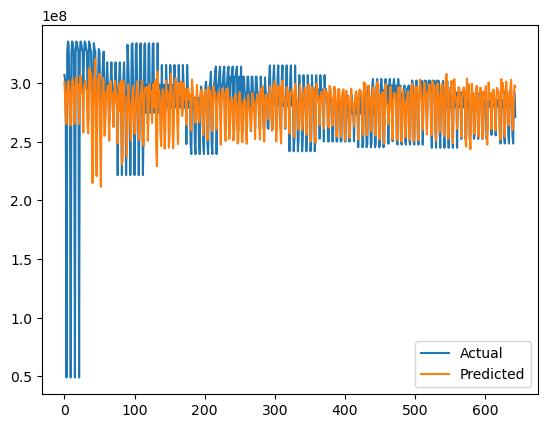

In [9]:
y_pred = best_model.predict(X_val)
y_pred_real = scaler_y.inverse_transform(y_pred)
y_val_real = scaler_y.inverse_transform(y_val)

plt.plot(y_val_real.flatten(), label="Actual")
plt.plot(y_pred_real.flatten(), label="Predicted")
plt.legend()
plt.show()

Create and format CSV file

In [13]:
last_date = df_daily['measurement_date'].max()

rows = []
for i, row in enumerate(y_pred_real):
    for horizon_day, forecast in enumerate(row, start=1):
        forecast_date = last_date + timedelta(days=horizon_day)
        rows.append({
            "horizon_day": horizon_day,
            "forecast_energy": int(forecast),
            "forecast_date": forecast_date
        })

df_forecast = pd.DataFrame(rows)
df_forecast.to_csv("../database/data/lstm_pred_long.csv", index=False)